# Lesson 8 | Deep Learning

# 8.2 Tensorflow and Keras

*   Installing TensorFlow
*   Loading images

In [5]:
!uv add tensorflow

Resolved 146 packages in 20ms
Checked 77 packages in 25ms


If you don't have a GPU on your computer, this is all you need. With a
GPU the setup is a bit more involved. I'm not an expert in that - I
usually prefer cloud solutions where everything is already configured,
so I can just create a notebook and start training. Later in this
module I use Amazon SageMaker notebooks that already have TensorFlow
installed. In this video I still use my laptop - you can see it's
localhost.

## Importing the libraries

Once installed, we import TensorFlow and Keras:

In [6]:
import tensorflow as tf
from tensorflow import keras

In [11]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Loading an image

Now let's load one of the images from the clothing dataset. There is a
special function in Keras for that - `load_img`:

In [7]:
from keras.preprocessing.image import load_img

If you find older tutorials online, you may see the import written as
`from tensorflow.keras.preprocessing.image import load_img`, with
`tensorflow` behind. That was valid when Keras was a separate
library. You can take such code, add `tensorflow` behind, and it
should work without changes.


Let's load a t-shirt from the train folder. We build the path with an
f-string and pass it to `load_img`:

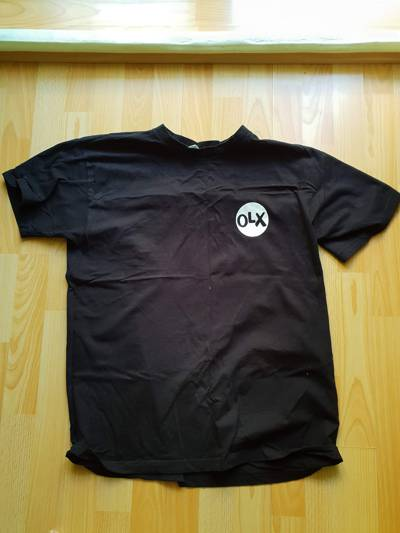

In [8]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

This is actually a Machine Learning Zoomcamp t-shirt - I think I even
recorded a couple of videos wearing it.

## Resizing with target_size

A neural network expects an image of a certain size. Common sizes are
299x299, 224x224, or smaller ones like 150x150:

<p align="center">
  <img src="./images/02-tensorflow-keras-05-image-sizes.svg" alt="Common input sizes for neural networks: 299x299 and 224x224" width="640">
</p>

If we have an image of a different size, we need to resize it to one
of these formats. We do that with the `target_size` parameter:


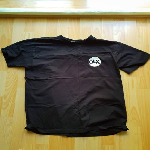

In [9]:
img = load_img(fullname, target_size=(150, 150))
img

In [10]:
print(img)

<PIL.Image.Image image mode=RGB size=150x150 at 0x10B8DFA10>


The library behind this is PIL - the Python Imaging Library. It's what
many libraries use for processing images, and `load_img` returns a PIL
image.

## How images are represented

Internally, an image is just an array with three channels: red, green
and blue. Each channel is an array, and each cell of that array is a
number between 0 and 255 - that's one byte:

<p align="center">
  <img src="./images/02-tensorflow-keras-07-rgb-channels.svg" alt="An image as three channels; the green channel is a grid of numbers from 0 to 255" width="640">
</p>

Each pixel combines three values: one from the red channel, one from
the green channel and one from the blue channel. Our t-shirt is almost
black, so for a pixel on the shirt all three values are probably
almost zero.

## From image to NumPy array

We can turn a PIL image into a NumPy array by simply wrapping it in
`np.array`:

In [ ]:
x = np.array(img) # many columns and rows about image (RGB) in each pixel  | unsign integer
x [:3, :3]

array([[[177, 169,  97],
        [178, 169, 100],
        [182, 173, 104]],

       [[200, 190, 128],
        [203, 193, 132],
        [203, 193, 132]],

       [[200, 189, 133],
        [203, 192, 136],
        [202, 191, 135]]], dtype=uint8)

In [24]:
x.shape

(150, 150, 3)

The shape is `(150, 150, 3)`: height, width, and the number of
channels. Each row of the array is one pixel with its RGB values -
the first number is red, the second green, the third blue. We have
150x150 of them.


The dtype is `uint8`. "u" means unsigned - the values go from 0 to
255, not from -128 to 127 - and "int8" means an integer that takes
eight bits, or one byte.

That's our image as a NumPy array. In the next video we'll see how to
use a pre-trained convolutional neural network to understand what is
on this image.


### Notes

<details>

In the video the `load_img` function from Keras is imported using

```python
from tensorflow.keras.processing.image import load_img
```

If the import is not working, try using

```python
from tensorflow.keras.utils import load_img
```

[Tensorflow documentation](https://www.tensorflow.org/api_docs/python/tf/keras/utils/load_img)

**Classes, functions, and methods**:

- `import tensorflow as tf`: to import tensorflow library
- `from tensorflow import keras`: to import keras
- `from tensorflow.keras.preprocessing.image import load_img`: to import load_img function
- `load_img('path/to/image', targe_size=(150,150))`: to load the image of 150 x 150 size in PIL format
- `np.array(img)`: convert image into a numpy array of 3D shape, where each row of the array represents the value of red, green, and blue color channels of one pixel in the image.

* tensorflow and keras as deep learning libraries
* end-to-end open source machine learning framework
* tensorflow as library for training deep learning models
* keras as high-level abstraction on top of tensorflow
* installing tensorflow
* local vs cloud configuration
* loading and preprocessing images
* keras is part of tensorflow since version 2.0
* working with different image sizes
* processing images using the python pillow library
* encoding images as numpy arrays
* image size (i.e. 150 x 150 pixels) multiplied by number of colors (i.e. RGB) equals shape of array
* numpy array dtype as unsigned int8 (uint8) which includes the range from 0 to 255

# 8.3 Pre-trained convolutional neural networks

In the previous lesson we installed TensorFlow and Keras and learned
how to load images. Now we take the image of a t-shirt and run it
through an off-the-shelf neural network - a model that somebody else
already trained and made available - and see what it tells us about
the image.


## Keras Applications and ImageNet

The pre-trained models live on the Keras website, on the page called
Keras Applications. It has a list of available pre-trained models.
Most of them (I think all of them) were trained on ImageNet.

ImageNet is a dataset with a lot of images. On its website we can see
that it spans 1000 object classes and has almost 1,300,000 images in
the training set, 50,000 in validation and 100,000 in test:

<p align="center">
  <img src="./images/03-pretrained-models-02-imagenet-crisp.jpg" alt="The ImageNet website: 1000 classes, over a million training images" width="640">
</p>

We will not download it - it's huge. It contains all sorts of animals,
objects, wheels, yachts, planes, nature, people, even clothes. It's a
dataset for general-purpose image classification.

Big companies like Google or Facebook, or big universities with access
to a lot of data and cool computers, took this dataset, took some
neural networks, trained them on ImageNet and shared the results. The
results are the models on the Keras Applications page:


There are different kinds of models - Xception, VGG, ResNet and many
others. They have different so-called architectures: an architecture
is how exactly the layers of a neural network are arranged inside a
model. For each model the page reports statistics: the size, the top-1
and top-5 accuracy, the number of parameters, how fast the model is.
We can use these characteristics to decide which one to take.

I usually choose Xception: it's a small model, quite accurate and also
quite fast. Maybe there are faster ones, but it has an okay trade-off
between size, accuracy and speed.


## Running on a GPU

Before I was running TensorFlow locally, but now let me use SageMaker.
I created an instance there - this instance type has a GPU:

<p align="center">
  <img src="./images/03-pretrained-models-03-sagemaker-gpu-crisp.jpg" alt="An Amazon SageMaker notebook instance with a GPU" width="640">
</p>

A GPU is needed if you want to run things faster. You can run on your
usual processor (CPU), but it will be around 8 times slower. GPUs are
very good at parallelizing things - they are fast at matrix
multiplication and other number-crunching operations, and this is what
neural networks are mostly about.

You don't have to use SageMaker: Google Cloud, Kaggle or any other
cloud solution works too, or you can simply run things locally. I
uploaded the same notebook as before, selected the TensorFlow kernel
and executed the previous cells.


## Using the Xception model

Xception lives in `keras.applications.xception`, so we import it from
there:

In [25]:
from keras.applications.xception import Xception
from keras.applications.xception import preprocess_input
from keras.applications.xception import decode_predictions

Then we create the model:

In [32]:
img = load_img(fullname, target_size=(299, 299))
x = np.array(img)

In [26]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


The first parameter, `weights='imagenet'`, means we want the network
that was pre-trained on ImageNet. The input to this model is 299x299x3
- so we also load our t-shirt image with `target_size=(299, 299)`:


The first time you run this, it downloads the model from the internet
and unpacks it, so it takes some time:


Now we want to use this model to classify the image of the t-shirt.
The model doesn't expect just one image - it expects a bunch of
images. So we create a NumPy array with our image inside:


In [33]:
X = np.array([x])
X.shape

(1, 299, 299, 3)

## Preprocessing

If we call `model.predict` now, the predictions won't make sense - we
mostly see zeros and super tiny numbers. The reason: this model
expects the input to look a certain way. When Xception was trained,
all the images were preprocessed with a special function, so we have
to apply exactly the same function to our data:

In [34]:
X = preprocess_input(X)

After preprocessing, our image no longer contains numbers between 0
and 255 - they are converted to numbers between -1 and 1:


We have to do this if we want the model to function correctly, because
this is the preprocessing that was used for training it.

Now the predictions make more sense:

In [35]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step


(1, 1000)

The shape is `(1, 1000)` - 1000 classes, one image. Each value in this
array is the probability that our image belongs to that class.

## Decoding the predictions

To make sense of this output we need to know which class each of the
1000 values corresponds to. There is another function in the Xception
package - `decode_predictions`. It looks at the predictions and makes
them human-readable, downloading the mapping from indices to class
names:

In [36]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


[[('n03595614', 'jersey', np.float32(0.68196315)),
  ('n02916936', 'bulletproof_vest', np.float32(0.03814001)),
  ('n04370456', 'sweatshirt', np.float32(0.034324795)),
  ('n03710637', 'maillot', np.float32(0.011354201)),
  ('n04525038', 'velvet', np.float32(0.0018453585))]]

The top class is jersey with probability 0.68. Jersey is an item of
knitted clothing, usually made of wool or cotton. It's not exactly a
t-shirt - but it's also not very far. At least the model didn't say
this is a dog or a plane. The other suggestions are a bulletproof
vest, a sweatshirt, a maillot and velvet - related items, but not
really what we need.

## Why it doesn't work for us

The reason is in the ImageNet classes themselves. If we look at the
list, there are all sorts of things - but there's no t-shirt. There
are sweatshirts, but no <u>**t-shirts and no simple shirts**</u>.

Even though ImageNet is big, comprehensive and general, when it comes
to clothes and fashion it's not particularly good. So this model
doesn't work for our purpose. Remember what we wanted: suggest a
proper category to the users of our website when they create a
listing. For that we need to train a different model, with the classes
we need for our particular case.

The good news: we don't have to train from scratch. We can reuse
these pre-trained models and build on top of what big companies and
universities have already trained, adapting them to our use case.
That's what we will do soon. But in the next video we'll first look
under the hood of neural networks to get some intuition for how they
work.

<p align="center">
  <img src="./images/03-pretrained-models-01-pretrained-model-fails.svg" alt="A pre-trained ImageNet model answers 'jersey' instead of a shop category, so the listing can't be published" width="640">
</p>


## Materials

- [Slides](https://www.slideshare.net/AlexeyGrigorev/ml-zoomcamp-8-neural-networks-and-deep-learning-250592316)
- [Renting a GPU with AWS SageMaker](https://livebook.manning.com/book/machine-learning-bookcamp/appendix-e/6)
- [Keras Applications](https://keras.io/api/applications/)
- [ImageNet](https://www.image-net.org/)

## Notes

> **Important**: If you rent a GPU from a cloud provider (such as AWS), don't forget to turn it
> off after you finish. It's not free and you might get a large bill at the end of the month.

- The `keras.applications` module has different pre-trained models with different architectures. We'll use the model [Xception](https://keras.io/api/applications/xception/) which takes the input image size of `(229, 229)` and each image's pixel is scaled between `-1` and `1`.
- We create the instance of the pre-trained model using `model = Xception(weights='imagenet', input_shape=(299, 229, 3))`. Our model will use the weights from pre-trained imagenet and expect the input shape of (229, 229, 3) for images.
- Along with image size, the model also expects the `batch_size` which is the size of the batches of data (default 32). If one image is passed to the model, then the expected shape of the model should be (1, 229, 229, 3).
- The image data was peprocessed using `preprocess_input` function during `Xception` model's pre-taining. Therefore, we'll have to use this function on our data before making predictions, like so: `X = preprocess_input(X)`.
- The `pred = model.predict(X)` function returns 2D array of shape `(1, 1000)`, where 1000 is the probablity of the image classes. `decode_predictions(pred)` can be used to get the class names and their probabilities in readable format.
- In order to make the pre-trained model useful specific to our case, we'll have to do some tweak, which we'll do in the coming sections.

**Classes, functions, and methods**:
- `from tensorflow.keras.applications.xception import Xception`: import the model from keras applications
- `from tensorflow.keras.application.xception import preprocess_input`: function to perform preprocessing on images
- `from tensorflow.keras.applications.xception import decode_predictions`: extract the predictions class names in the form of tuple of list
- `model.predict(X)`: function to make predictions on the test images

**Links**:

- [Renting a GPU with AWS SageMaker](https://livebook.manning.com/book/machine-learning-bookcamp/appendix-e/23)
- [Keras Applications](https://keras.io/api/applications/) provide a list of pre-trained deep learning models
- [ImageNet](https://www.image-net.org/) is an image database that has 1,431,167 images of 1000 classes

# 8.4 Convolutional neural networks

The model we used in the previous unit, Xception, is a convolutional
neural network. In this unit we go inside it: what convolutional
layers and dense layers are, how filters turn an image into a vector
representation, and how that vector becomes a prediction.


## What is inside a CNN

Convolutional neural networks (CNNs) are the type of neural networks
used mostly for images. They consist of different types of layers, and
one of them is called a convolutional layer - that's where the name
comes from.

We have an image, and we want a neural network to predict what is on
it. We feed the image to a CNN - for now, think of it as a black box -
and it outputs a prediction: this is a t-shirt.

<p align="center">
  <img src="./images/04-conv-neural-nets-01-cnn-overview.svg" alt="Image goes into a CNN with many layers and comes out as a prediction" width="640">
</p>

Inside the box there are layers - layer one, layer two, and so on,
possibly quite a few of them. There are two main types of layers in a
convolutional neural network:

- Convolutional layers
- Dense layers

## Convolutional layers and filters

Convolutional layers consist of filters. A filter is kind of a small
image - usually quite small, like 5x5, sometimes even smaller - and
there are quite a few of them in a layer.

The filters contain simple shapes: simple lines, stripes, circles.
This is just an example, not a real network - it's to give you an
understanding of what might be happening inside.

We take our image, take a filter, and slide this filter across the
image. Every time we apply the filter, we check how similar the filter
is to the part of the image it currently covers. The similarity is a
number: zero usually means no similarity, a higher number means bigger
similarity.

We record this number for each position of the filter. The resulting
array is called a feature map:

<p align="center">
  <img src="./images/04-conv-neural-nets-02-feature-map.svg" alt="Sliding a filter across the image and recording the similarity at each position gives a feature map" width="640">
</p>

The feature map is the result of applying one filter to an image: we
slide the filter across the image, compute the similarity at every
position, and record it. High values mean the filter is similar to
that part of the image. In this drawing, the filter matched somewhere
in the middle (the 9), and the rest is mostly zeros.

We do this for each filter. If a convolutional layer has six filters,
it produces six feature maps - one feature map per filter:

<p align="center">
  <img src="./images/04-conv-neural-nets-03-one-feature-map-per-filter.svg" alt="The image and six filters produce a stack of feature maps - one per filter" width="640">
</p>

## Chaining convolutional layers

The output of the first convolutional layer is a set of feature maps.
We can treat this output as a new image - an image that we made from
the original one - and feed it to another convolutional layer. This
layer has its own set of filters, applies them to the output of the
first layer, and produces its own feature maps:

<p align="center">
  <img src="./images/04-conv-neural-nets-04-chained-conv-layers.svg" alt="Chained convolutional layers: 6 filters produce 6 feature maps, then 12 filters produce 12 feature maps" width="640">
</p>

Here the first layer has 6 filters and produces 6 feature maps, the
second has 12 filters and produces 12 feature maps, and we can keep
going with a third layer.

Because of this chaining, each layer learns more and more complex
filters. These filters are what a neural network learns during
training. The first convolutional layer typically learns simple
filters - just stripes. The second layer combines the filters from the
first layer: a circle can be a combination of two stripes, an angle
can be two lines put together, a cross as well. By the third layer the
shapes are even more complex.

So the first layer recognizes simple patterns - stripes; where the
image has a similar stripe, the feature map has a high value. Using
this information, the second layer can detect more complex shapes -
circles or angles. And the third layer can detect things like sleeves.
Each layer detects progressively more complex features: low-level
features first, then mid-level, then high-level features of the image.

<p align="center">
  <img src="./images/04-conv-neural-nets-05-low-mid-high-level-features.svg" alt="Each convolutional layer learns more complex features: low-level stripes, mid-level corners and circles, high-level parts like sleeves" width="640">
</p>

By "features" I mean things like "there are sleeves in this part of
the image" or "there is a circle in this specific area". This is not
exactly how filters look in reality, but it's a good way to think
about them. What filters actually do is look at a region across all
the values of all the feature maps in that region - they go in depth.
A higher-level filter can fire when, say, two lower-level feature maps
both have high values in the same area. This way, the more layers we
have, the more complex features we can capture. And remember - all
these filters are learned automatically. We don't tell the network
"make a filter for this kind of line". It learns them during training.

## Vector representation

We take our image and pass it through a set of convolutional layers.
The result of this is a vector representation of the image:

<p align="center">
  <img src="./images/04-conv-neural-nets-05-vector-representation.svg" alt="The image (299x299x3) goes through convolutional layers and comes out as a vector of 2048 numbers" width="640">
</p>

If the input image is 299x299x3, the vector representation could be
something like 2048 numbers - a one-dimensional array. The
dimensionality is usually 2048 or 1024 - typically powers of two.

This vector captures the information about the image. There could be
an area that says there are sleeves, an area that corresponds to
color, an area for some other part of the image, and so on. It's very
hard for people to make sense of these numbers, but for neural
networks they make sense, and they contain all the information the
network was able to extract from the image.

So the role of convolutional layers is to extract this vector
representation.

## Dense layers

With this vector we can build a model that makes the final prediction.
Dense layers take the vector representation and turn it into
predictions.

Let's start with binary classification: is this a t-shirt, or not? The
input x is the vector representation of the image, and the target y is
0 (not a t-shirt) or 1 (t-shirt). For this we usually use logistic
regression: g(x) is a sigmoid. The weights are trained, and the output
is the probability that x is a t-shirt:

<p align="center">
  <img src="./images/04-conv-neural-nets-06-logistic-regression.svg" alt="Each element of x is multiplied by its weight, everything is summed, and sigmoid turns the sum into a probability" width="640">
</p>

Concretely: the elements of x are x1, x2, x3, up to xn. We multiply
each of them by its weight - w1, w2, w3, and so on - and sum everything
together. Then we apply the sigmoid to this sum to turn it into a
probability of being a t-shirt.

Now let's imagine we want multiple classes: in addition to t-shirt, a
shirt and a dress. We can build three models, one per class. Each model
gets the same input - the vector representation - but each has its own
set of weights: red ones for t-shirts, green ones for shirts, blue
ones for dresses.

Instead of sigmoid, for multiple classes we use softmax - it's a
generalization of sigmoid to multiple classes. The output is a
three-dimensional vector: the first component is the probability of
shirt, the second of t-shirt, the third of dress.

<p align="center">
  <img src="./images/04-conv-neural-nets-07-softmax-multiclass.svg" alt="x is connected to one weighted sum per class - shirt, t-shirt and dress - and softmax turns the three sums into probabilities" width="640">
</p>

What we have done here is put multiple logistic regressions together -
and as a result we got a neural network.

This layer is called a dense layer. The input to the layer is the
vector representation, and the output is the predictions:

<p align="center">
  <img src="./images/04-conv-neural-nets-07-dense-layer.svg" alt="A dense layer connects each element of the input with each element of the output" width="640">
</p>

It's called "dense" because each element of the input is connected to
each element of the output - there are a lot of connections, the area
is really dense. For each output we have a weight: w1, w2, w3, and so
on. If we put all these w's together, we get one big matrix W, where
each row is the w of one output. If x is a column vector, then to
transform the input to the output, all we need to do is multiply W by
x. A dense layer is nothing else but matrix multiplication.

We can put multiple dense layers together. The layer between the input
and the final predictions is called an inner dense layer, and the last
one is the final dense layer for predictions.

## Back to our problem

For our clothing classifier: we take the image, turn it into a vector
representation with convolutional layers, convert this vector into
some inner representation with a dense layer, and then finally convert
it to the output - 10 values, one per class. From this output we
select the one with the highest value, and hopefully it's t-shirt:

<p align="center">
  <img src="./images/04-conv-neural-nets-08-inner-dense-layer.svg" alt="The image becomes a vector representation through conv layers, an inner dense layer turns it into an inner representation, and the output dense layer gives 10 values, one per class" width="640">
</p>

<p align="center">
  <img src="./images/04-conv-neural-nets-08-summary.svg" alt="The summary: convolutional layers, then the vector representation, then dense layers, then the prediction" width="640">
</p>

That's the whole picture. Of course, here I only scratched the surface
of how convolutional neural networks work. If you want to go deeper,
check [CS231n](https://cs231n.github.io/), the Stanford course I
mentioned in the first lesson - they go into a lot of detail about how
these layers work, with very nice visualizations of the learned
filters and feature maps.

There's also a great interactive website where you can play with a CNN
right in the browser: [CNN Explainer](https://poloclub.github.io/cnn-explainer/).

One type of layer we didn't talk about is pooling layers. The purpose
of pooling is to make the feature maps smaller - it takes a feature
map and shrinks it, for example from 200x200 to 100x100. The reason
for doing this is to make the neural network smaller, to force it to
have fewer parameters. If you're interested, go through the CS231n
notes - they're really good. It's not required, but recommended.

In the next lesson we will see how this theory is useful: how to use
the convolutional part for extracting the vector representation and
how to train dense layers for our purpose.

## Notes

A convolutional neural network, also know as CNN or ConvNet, is a feed-forward neural network that is generally used to analyze visual images by processing data with grid-like topology. A CNN is used to detect and classify objects in an image. In CNNs, every image is represented in the form of an array of pixel values.

The convoluion operation forms the basis of any CNN. In a convolution operation, the arrays are multiplied element-wise, and the dot product is summed to create a new array, which represents `Wx`.

A Convolution neural network has multiple hidden layers that help in extracting information from an image. The four important layers in CNN are:

1. Convolution layer
2. ReLU layer
3. Pooling layer
4. Fully connected layer (also called Dense layer)

**Convolution layer**

This is the first step in the process of extracting valuable features from an image. A convolution layer has several filters that perform the convolution operation. Every image is considered as a matrix of pixel values.

Consider a black and white image of 5x5 size whose pixel values are either 0 or 1 and also a filter matrix with a dimension of 3x3. Next, slide the filter matrix over the image and compute the dot product to get the convolved feature matrix.

```python
nn.Conv2d(
    in_channels,      # number of channels in the input image
    out_channels,     # number of filters to learn
    kernel_size,      # size of each filter (int or tuple)
    stride=1,         # step size for moving the filter
    padding=0,        # zero-padding around input
)
```

Explanation:

* in_channels: Input depth (e.g., 3 for RGB images).
* out_channels: Number of filters the layer will learn. Each produces one output feature map.
* kernel_size: Size of the convolutional filter. Can be a single number (square filter) or a tuple (height, width).
* stride: How many pixels the filter moves each step. Default is 1.
<p align="center">
  <img width="580" height="330" alt="image" src="https://github.com/user-attachments/assets/3cfca38d-56bd-4a51-a3ce-70d8c071d4c8" />
</p>
* padding: Number of pixels added around the input to control output size. Default is 0.
<p align="center">
  <img width="550" height="280" alt="image" src="https://github.com/user-attachments/assets/5465dc2e-402d-41c9-a6fb-3ecfdc384796" />  <img width="270" height="280" alt="image" src="https://github.com/user-attachments/assets/c8a57bb4-c454-4169-b18c-41b79449bbe6" />
</p>

Output size after Conv2d image

$$\text{Output size} = \frac{W - K + 2P}{S} + 1$$

Where:
* 𝑊 = input size (height or width)
* 𝐾 = kernel size
* 𝑃 = padding
* 𝑆 = stride

**ReLU layer**

Once the feature maps are extracted, the next step is to move them to a ReLU layer. ReLU (Rectified Linear Unit) is an activation function which performs an element-wise operation and sets all the negative pixels to 0. It introduces non-linearity to the network, and the generated output is a rectified feature map. The relu function is: `f(x) = max(0,x)`.

**Pooling layer**

Pooling is a down-sampling operation that reduces the dimensionality of the feature map. The rectified feature map goes through a pooling layer to generate a pooled feature map.

Imagine a rectified feature map of size 4x4 goes through a max pooling filter of 2x2 size with stride of 2. In this case, the resultant pooled feature map will have a pooled feature map of 2x2 size where each value will represent the maximum value of each stride.

The pooling layer uses various filters to identify different parts of the image like edges, shapes etc.

**Fully Connected layer**

The next step in the process is called flattening. Flattening is used to convert all the resultant 2D arrays from pooled feature maps into a single linear vector. This flattened vector is then fed as input to the fully connected layer to classify the image.

**Convolutional Neural Networks in a nutshell**

- The pixels from the image are fed to the convolutional layer that performs the convolution operation
- It results in a convolved map
- The convolved map is applied to a ReLU function to generate a rectified feature map
- The image is processed with multiple convolutions and ReLU layers for locating the features
- Different pooling layers with various filters are used to identify specific parts of the image
- The pooled feature map is flattened and fed to a fully connected layer to get the final output

* convolutional neural networks (CNN) consist of different types of layers
* convolutional layer as filters (i.e. 5 x 5)
* dense layers
* sliding the filter across the cells of the entire image
* calculating similarity scores of the different positions of the filter
* creating the feature map, one feature map per filter
* chaining layers of simple and complex filters allows the CNN to "learn"
* resulting in vector representation of image
* activation functions sigmoid for binary classification and softmax for multiclass

# 8.5 Transfer learning

In the previous unit we looked at the internals of convolutional
neural networks: convolutional layers turn an image into a vector
representation, and dense layers use that vector to make predictions.
In this unit we put that to use: we take a neural network that is
already pre-trained - a model trained on ImageNet - and reuse it for
our task. This idea is called transfer learning.

## The idea

Remember that each layer of a neural network contains a bunch of
filters. These filters are learnable - the model learns them during
training - and the filters it learns are quite generic: they can be
used for many purposes.

Somebody trained this model on the ImageNet dataset. Training these
filters in the convolutional layers is very difficult: the model needs
to see a huge amount of images to come up with filters that make
sense. But once trained, the model can take any picture and convert it
into a vector representation - and this is quite generic. We don't
need to change it for our task.

The dense layers are a different story. They are specific to the
dataset the model was trained on. ImageNet has 1000 different classes,
so the output dense layer has a size of 1000. In our problem we want
to predict only 10 classes - and many of them, like t-shirt, don't
even exist in ImageNet.

<p align="center">
  <img src="./images/05-transfer-learning-01-transfer-learning-idea.svg" alt="The convolutional layers are generic and stay; the dense layers are specific to ImageNet and get replaced" width="640">
</p>

So the plan is:

- Keep the convolutional layers - they already know how to turn an
  image into a vector representation.
- Throw away the dense layers from ImageNet and train our own dense
  layers for our 10 classes.

Everything the model learned previously - the most difficult part - is
reused, and we transfer this knowledge to a new model. That's the main
idea behind transfer learning.

## Reading the data

Let's see how to do it with Keras. The first thing we need is to read
our dataset. There is a special class for that, `ImageDataGenerator`.
It lives in `tensorflow.keras.preprocessing.image`:

In [40]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # legacy path, still exported and the class is DEPRECATED

Let's create one for training:

In [41]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


he only thing we specify for now is the preprocessing function - the
same `preprocess_input` we used previously with Xception. From this
generator we call `flow_from_directory` to read images from a
directory.

The target size is 150x150 for now. This way we can experiment faster:
training on 299x299 images would take four times more time, because a
299x299 image is four times bigger than a 150x150 one. For
experiments, we use smaller images, and at the end we'll retrain on
bigger ones.

The batch size is how many images we process at once: not one image,
but 32. So one batch has the shape `(32, 150, 150, 3)` - 32 images,
each 150x150, with 3 channels. The batch goes through the
convolutional layers, we get 32 vectors - one per image - and 32
predictions at the end.

When we execute this cell, it says that in the train folder it found
3068 images belonging to 10 classes:


We can look at which classes it found with `train_ds.class_indices`:

In [42]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

The first class is dress, then hat, longsleeve, outwear, pants, and so
on - t-shirt is the last one. These are the same names as the folders
in the train directory: the generator inferred the names of the
classes from the folder structure. Everything inside the t-shirt
folder gets the t-shirt class.

The train dataset is a generator - an iterator. To get the next batch,
we use the `next` function (a for loop invokes it internally):

In [49]:
X, y = next(train_ds)
X[:3,:3, 0], y[:5]

(array([[[ 0.6392157 ,  0.6       ,  0.5529412 ],
         [ 0.64705884,  0.60784316,  0.56078434],
         [ 0.654902  ,  0.6156863 ,  0.5686275 ]],
 
        [[ 0.5686275 ,  0.20784318, -0.27843136],
         [ 0.6       ,  0.23921573, -0.24705881],
         [ 0.5921569 ,  0.2313726 , -0.25490195]],
 
        [[-0.5921569 , -0.92156863, -0.8901961 ],
         [-0.56078434, -0.9137255 , -0.8745098 ],
         [-0.5372549 , -0.90588236, -0.85882354]]], dtype=float32),
 array([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]], dtype=float32))

In [47]:
X.shape

(32, 150, 150, 3)

It returns two things: X, the features (the images), and y, the
labels. X is very similar to what we saw previously - a bunch of
images with the `preprocess_input` function applied, because we asked
for it. The shape is `(32, 150, 150, 3)`, exactly like we wrote.

Let's also look at y - the labels. In the same screenshot above you
can see the first rows of `y[:5]`: the labels use one-hot encoding.
For example, the column of t-shirts is index 9 - the rows with a 1 in
the last column are t-shirts. This row here has a 1 in column 4,
pants: it has a 1 for pants and 0 everywhere else. It's the same
one-hot encoding method, but applied to the target variable. This is
how we usually do multi-class classification.

You can also think of it as 10 different binary variables: each column
says if this image is pants or not pants, dress or not dress, and so
on. We sort of fit 10 different binary classification models, even
though we actually fit only one.

We do the same for validation:

In [50]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


Everything is the same, except that here we don't shuffle: by default
the generator shuffles the dataset, but for validation that's not
needed - it's fine if the images always come in the same order. This
one finds 341 images belonging to the same 10 classes. Right below it
we can already start writing the base model.

## Building the model

Now let's train a model. We call the pre-trained part the base model,
and we'll train our custom model on top of it. The base model is
Xception, and we use it to extract the vector representation from the
image. Then we train the rest ourselves.

In [51]:
base_model = Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.trainable = False

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


We say `weights='imagenet'` to use the ImageNet weights. The other
parameter is `include_top=False`. In Keras the mental model is a bit
different - the network is arranged from bottom to top: at the bottom
we have the input, then the convolutional layers, which produce the
vector representation, and at the top a bunch of dense layers that
make the prediction. This dense part is called the "top".
`include_top=False` means: do not include the dense layers, only the
convolutional layers. The last parameter, `input_shape`, is
150x150x3.

<p align="center">
  <img src="./images/05-transfer-learning-02-keras-top-bottom.svg" alt="In Keras the network goes bottom to top: input, frozen convolutional layers, vector representation, and the dense 'top', which include_top=False removes so we can create a new one" width="640">
</p>

We don't want to train the base model - we only want to use it for
extracting the vector representation. So we say
`base_model.trainable = False`, meaning that when we train our model,
the convolutional layers don't change.

Executing this cell downloads the model, because for this input shape
it's a different model than the one we used before.

Now we create the new top. First, the input - the part of the model
that receives the images:

In [56]:
inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs, training=False)

outputs = base

outputs = keras.Model(inputs, outputs)

In [57]:
preds = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [58]:
preds.shape

(32, 10)

The input shape is 150x150x3 - a bit redundant, but we need to repeat
it. This input goes to the base model: we apply `base_model` to
`inputs` and call the output `base`. Remember that inputs is a batch -
32 images of 150x150x3.

What exactly comes out of the base model? For our batch it's a
four-dimensional thing with shape `(32, 5, 5, 2048)` - the first
dimension is the batch size. For a single image, what we get from the
convolutional layers is a three-dimensional thing: 5x5x2048.

This doesn't look like a vector representation yet, because it's
three-dimensional. We want to turn it into a one-dimensional vector.
For that we can slice this 5x5x2048 thing into 2048 squares of 5x5,
take the average of each square, and put that average into the vector:

<p align="center">
  <img src="./images/05-transfer-learning-05-pooling-vectors.svg" alt="Pooling: the 5x5x2048 output of the base model becomes one vector per image" width="640">
</p>

In [70]:
inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs, training=False)

vectors = keras.layers.GlobalAveragePooling2D()(base)

outputs = keras.layers.Dense(10)(vectors)

model = keras.Model(inputs, outputs)

In [71]:
preds = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 795ms/step


In [72]:
preds.shape

(32, 10)

In [73]:
preds[0]

array([ 0.6701822 , -0.52542096,  0.03316969,  0.21268308,  0.72618157,
       -0.33040687, -0.58255136,  0.5523977 , -0.58810407, -0.6612955 ],
      dtype=float32)

Taking something and representing it in a smaller dimensionality is
called pooling. Here we need average pooling, because we take an
average of each square. And because we turn a two-dimensional chunk
into a single number - a three-dimensional thing into a
one-dimensional thing - in Keras this layer is called
`GlobalAveragePooling2D`. We apply it to `base` and get the vectors.
Now the shape is `(32, 2048)`: we managed to shrink each image into a
one-dimensional vector of 2048 numbers.

By the way, this way of building a neural network - using these
building blocks as functions - is called the functional style. The
base model is actually a model, but we just invoke it as a function:
the input is `inputs`, the output is `base`. Then the pooling layer's
input is `base` and its output is `vectors`.

The last step: we want a dense layer on top to turn the vectors into
predictions. The output we want is an array of shape `(32, 10)` - 10
numbers per image, because we have 10 classes:

```python
outputs = keras.layers.Dense(10)(vectors)
```

So the whole picture: the t-shirt image goes to inputs, from there to
the base model, which produces the 5x5x2048 thing; pooling turns it
into the vector representation; and a dense layer with 10 outputs
turns the vector into predictions. We wrap it all in
`keras.Model(inputs, outputs)` and call this model version one.

Note that if we call `model.predict` now, it outputs some nonsense -
just random numbers. That's because the dense layer is initialized
with random weights, and we haven't trained the model yet.

## Optimizer and loss

To train the model we need two things: an optimizer and a loss.

The optimizer is the thing that finds the best weights for the model.
Remember the dense layer is a matrix W - training means changing each
element of this matrix and checking whether the solution gets better,
many many times. The optimizer does that. It doesn't change the
weights randomly - it tries to change them in such a way that the
model actually learns something.

Optimizers live in `keras.optimizers`. There are quite a few, and we
will use Adam. A really good resource to learn more about optimizers
is again CS231n - it explains gradient descent, which is what
optimizers use for finding the best parameters, and it says that in
practice Adam is currently recommended as the default algorithm. So
usually the recommendation is just to go with Adam.

In [67]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

Adam has multiple parameters, but the important one for us is the
learning rate. It's similar to eta in XGBoost. We'll talk about tuning
this parameter in the next lesson.

The optimizer needs to know how to check whether changing the weights
made things better or worse. For that there is the concept of loss:
the loss tells us how good the model is. Losses live in
`keras.losses`. Since this is a multi-class classification problem,
we use categorical cross-entropy. For binary classification we would
use binary cross-entropy, and for regression - mean squared error,
like in the earlier modules.

In [68]:
loss = keras.losses.CategoricalCrossentropy(from_logits=True)

Categorical cross-entropy outputs a number - the lower, the better -
and the optimizer tries to make it as low as possible by changing the
parameters of our dense layers.

There is one interesting parameter here: `from_logits=True`. The docs
say that using `from_logits=True` may be more numerically stable, so
the recommendation is to use it. Here's what it means: remember the
dense layer - input, output, and then softmax applied on top. Softmax
is called an activation: it takes the raw output of the dense layer
and turns it into probabilities. This raw output is called logits. If
we don't apply softmax, we have raw scores - logits; if we apply it,
we have probabilities. With `from_logits=True` we say: keep the raw
scores, don't apply any activation. If we wanted probabilities, we
would use `from_logits=False` and add `activation='softmax'` to the
dense layer. We keep the raw scores.

Now we compile the model - something we need to do before training.
We say which optimizer to use, which loss, and which metrics we're
interested in monitoring - accuracy:

In [74]:
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

## Training the model

Now we're ready to train, with the `fit` method:

In [75]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 400ms/step - accuracy: 0.6669 - loss: 1.3312 - val_accuracy: 0.7097 - val_loss: 1.1613
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 37s 383ms/step - accuracy: 0.8041 - loss: 0.6609 - val_accuracy: 0.7801 - val_loss: 0.8370
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 38s 391ms/step - accuracy: 0.8830 - loss: 0.3351 - val_accuracy: 0.7742 - val_loss: 1.0396
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 38s 394ms/step - accuracy: 0.9166 - loss: 0.2249 - val_accuracy: 0.7713 - val_loss: 1.0588
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 33s 338ms/step - accuracy: 0.9426 - loss: 0.1697 - val_accuracy: 0.8065 - val_loss: 0.9139
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 34s 351ms/step - accuracy: 0.9641 - loss: 0.1062 - val_accuracy: 0.7918 - val_loss: 0.9718
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 36s 374ms/step - accuracy: 0.9791 - loss: 0.0702 - val_accuracy: 0.7801 - val_loss: 1.0897
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 35s 369ms/step - accuracy: 0.9804 - loss: 0.0614 - val_accu

We pass the training dataset and say for how many epochs we want to
run. One epoch is going over the dataset once. The dataset consists of
batches of 32 images each (the last batch can be smaller). We train
the model on one batch at a time - that's one iteration - and going
over all batches once is one epoch. So 10 epochs means going over the
data 10 times. For validation, we use the validation dataset.

Something is not right at first - the accuracy is low. The fix: it's
not enough to say `trainable=False` on the base model, we also need to
pass `training=False` when we apply it:

```python
base = base_model(inputs, training=False)
```

Also, `model.fit` returns a history object which contains all the
training information - useful to have, so let's capture it in a
variable.


Now training works: the accuracy on train grows, the loss goes down.
After the first epoch the validation accuracy is already 75%. Accuracy
means: for how many images did we predict the class correctly. Then
it's 80, and the loss on the training set becomes quite small - from
now on it starts to overfit a little bit: the training accuracy keeps
improving but the validation accuracy doesn't.

The results are saved in the history object - `history.history` is a
dictionary with everything we saw during training. The interesting
keys are `accuracy` (train) and `val_accuracy` (validation). We can
plot them: for training it almost reaches 1.0, and for validation it
quickly reaches about 80 and then just oscillates around 80 for the
rest of the iterations - sometimes it jumps up, sometimes down.

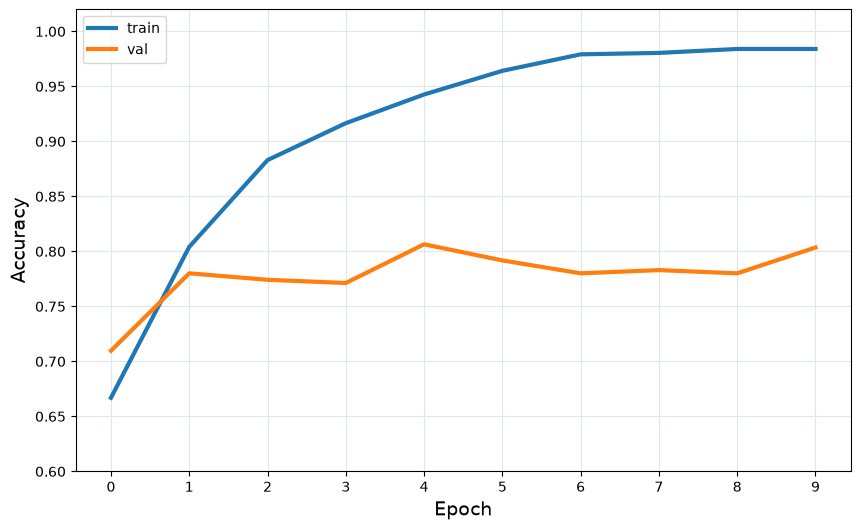

In [78]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.figure(figsize=(10, 6))
plt.plot(acc, linewidth=3, label='train')
plt.plot(val_acc, linewidth=3, label='val')

plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(range(len(acc)))
plt.ylim(0.6, 1.02)
plt.yticks(np.arange(0.6, 1.01, 0.05))
plt.grid(color='#e1e5ee')
plt.legend(loc='upper left')
plt.show()

With just these parameters - no tuning - we already have a reasonably
good model: about 80% validation accuracy. Of course, there are many
parameters we can try and tune. Like with gradient boosting, where the
most important parameter is eta - the learning rate - the same is true
for neural networks. The learning rate is the most important parameter
to tune, and that's exactly what we'll do in the next lesson.


### Notes

<details>
Transfer learning is a machine learning method where a model developed for a task is reused as the starting point for a model on a second task. Usually a pretrained model is trained with large volume of images and that is why the convolutional layers and vector representation of this model can be used for other tasks as well. However, the dense layers need to be retrained because they are specific to the dataset to make predictions with. In our problem, we want to keep convoluational layers but we want to train new dense layers.

Following are the steps to create train/validation data for model:

```python
# Build image generator for training (takes preprocessing input function)
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Load in train dataset into train generator
train_ds = train_gen.flow_from_directory(directory=path/to/train_imgs_dir, # Train images directory
                                         target_size=(150,150), # resize images to train faster
                                         batch_size=32) # 32 images per batch

# Create image generator for validation
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Load in image for validation
val_ds = val_gen.flow_from_directory(directory=path/to/val_imgs_dir, # Validation image directory
                                     target_size=(150,150),
                                     batch_size=32,
                                     shuffle=False) # False for validation
```

Following are the steps to build model from a pretrained model:

```python
# Build base model
base_model = Xception(weights='imagenet',
                      include_top=False, # to create custom dense layer
                      input_shape=(150,150,3))

# Freeze the convolutional base by preventing the weights being updated during training
base_model.trainable = False

# Define expected image shape as input
inputs = keras.Input(shape=(150,150,3))

# Feed inputs to the base model
base = base_model(inputs, training=False) # set False because the model contains BatchNormalization layer

# Convert matrices into vectors using pooling layer
vectors = keras.layers.GlobalAveragePooling2D()(base)

# Create dense layer of 10 classes
outputs = keras.layers.Dense(10)(vectors)

# Create model for training
model = keras.Model(inputs, outputs)
```

Following are the steps to instantiate optimizer and loss function:

```python
# Define learning rate
learning_rate = 0.01

# Create optimizer
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

# Define loss function
loss = keras.losses.CategoricalCrossentropy(from_logits=True) # to keep the raw output of dense layer without applying softmax

# Compile the model
model.compile(optimizer=optimizer,
              loss=loss,
              metrics=['accuracy']) # evaluation metric accuracy
```

The model is ready to train once it is defined and compiled:

```python
# Train the model, validate it with validation data, and save the training history
history = model.fit(train_ds, epochs=10, validation_data=val_ds)
```

**Classes, function, and attributes**:
- `from tensorflow.keras.preprocessing.image import ImageDataGenerator`: to read the image data and make it useful for training/validation
- `flow_from_directory()`: method to read the images directly from the directory
- `next(train_ds)`: to unpack features and target variables
- `train_ds.class_indices`: attribute to get classes according to the directory structure
- `GlobalAveragePooling2D()`: accepts 4D tensor as input and operates the mean on the height and width dimensionalities for all the channels and returns vector representation of all images
- `CategoricalCrossentropy()`: method to produces a one-hot array containing the probable match for each category in multi classification
- `model.fit()`: method to train model
- `epochs`: number of iterations over all of the training data
- `history.history`: history attribute is a dictionary recording loss and metrics values (accuracy in our case) for each epoch

* convolutional layers convert an image into a vector representation
* dense layers use vector representations to make predictions
* using a pretrained neural network
* imagenet has 1000 different classes
* a dense layer may be specific to a certain number of classes whereas the vector representation can be applied to another dataset
* reusing the vector representation from convolutional layers means transferring knowledge and the idea behind transfer learning
* train faster on smaller size images
* the batch size
* base model vs custom model
* bottom layers vs top layers in keras
* keras optimizers
* using the adam optimizer
* weights, learning rates
* eta in xgboost
* model loss
* categorical cross entropy
* changing accuracy during several training epochs
* overfitting

---

## Alternative - Image Detect from Directory
`image_dataset_from_directory` reads images from folders and gives you ready-to-train batches. I ran each part below on your dataset, and the outputs are real, but your first batch will differ because the data is shuffled. I tested training for only two batches with a tiny model, not Xception, to avoid downloading its weights.


### Step 1. How it finds the labels
Each subfolder name becomes a class, so you don't need a labels file:

```
clothing-dataset-small/train/
├── dress/      → class 0
├── hat/        → class 1
├── ...
└── t-shirt/    → class 9
```

In [87]:
inputs = keras.Input(shape=(150, 150, 3))
base = base_model(inputs, training=False)
vectors = keras.layers.GlobalAveragePooling2D()(base)
outputs = keras.layers.Dense(10)(vectors)
model = keras.Model(inputs, outputs)

optimizer = keras.optimizers.Adam(learning_rate=0.01)
loss = keras.losses.CategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

### Step 2. Load the data

In [79]:
from keras.utils import image_dataset_from_directory

train_ds = image_dataset_from_directory(
    './clothing-dataset-small/train',
    image_size=(150, 150),
    batch_size=32,
    label_mode='categorical'
)

val_ds = image_dataset_from_directory(
    './clothing-dataset-small/validation',
    image_size=(150, 150),
    batch_size=32,
    label_mode='categorical',
    shuffle=False
)

Found 3068 files belonging to 10 classes.
Found 341 files belonging to 10 classes.


### Step 3. See the classes
This replaces `train_ds.class_indices`

In [80]:
class_names = train_ds.class_names
class_names

['dress',
 'hat',
 'longsleeve',
 'outwear',
 'pants',
 'shirt',
 'shoes',
 'shorts',
 'skirt',
 't-shirt']

### Step 4. Look at one batch
**Run it before step 5**, because `.map` removes this attribute:

In [ ]:
X, y = next(iter(train_ds))
X.shape, y.shape

(TensorShape([32, 150, 150, 3]), TensorShape([32, 10]))

- `X`: 32 images, each 150×150 pixels with 3 color channels.
- `y`: 32 labels with 10 positions each, one per class.

In [83]:
X[:3, :3, 0], y[:2]

(<tf.Tensor: shape=(3, 3, 3), dtype=float32, numpy=
 array([[[169.19333 , 168.19333 , 164.19333 ],
         [165.21    , 164.21    , 160.21    ],
         [166.63333 , 165.63333 , 161.63333 ]],
 
        [[192.20166 , 184.20166 , 173.20166 ],
         [183.31833 , 175.31833 , 164.31833 ],
         [214.82222 , 206.82222 , 195.82222 ]],
 
        [[173.      ,  90.      ,  48.      ],
         [173.      ,  90.      ,  48.      ],
         [176.29723 ,  93.29722 ,  51.297222]]], dtype=float32)>,
 <tf.Tensor: shape=(2, 10), dtype=float32, numpy=
 array([[0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]], dtype=float32)>)

### Step 5. Preprocess the images
This replaces `preprocessing_function=preprocess_input`

In [84]:
train_ds = train_ds.map(lambda X, y: (preprocess_input(X), y))
val_ds = val_ds.map(lambda X, y: (preprocess_input(X), y))

The `lambda` receives a batch and returns the processed images with their labels unchanged. Pixel values go from `0 to 255` to `-1 to 1`, the range Xception expects.

### Step 6. Train
Your training code doesn't change:

In [88]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10


/Users/ifabela/Documents/iocode/DataTalks_club/ml-course-datatalksclub/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


96/96 ━━━━━━━━━━━━━━━━━━━━ 39s 397ms/step - accuracy: 0.6656 - loss: 1.2821 - val_accuracy: 0.7859 - val_loss: 0.8612
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 34s 355ms/step - accuracy: 0.8449 - loss: 0.4617 - val_accuracy: 0.7654 - val_loss: 0.8034
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 34s 357ms/step - accuracy: 0.8902 - loss: 0.3279 - val_accuracy: 0.7918 - val_loss: 0.8277
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 36s 375ms/step - accuracy: 0.9032 - loss: 0.2708 - val_accuracy: 0.7478 - val_loss: 1.2453
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 328ms/step - accuracy: 0.9192 - loss: 0.2163 - val_accuracy: 0.7947 - val_loss: 1.1061
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 324ms/step - accuracy: 0.9505 - loss: 0.1376 - val_accuracy: 0.7977 - val_loss: 0.9082
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 312ms/step - accuracy: 0.9550 - loss: 0.1090 - val_accuracy: 0.7683 - val_loss: 1.1985
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 336ms/step - accuracy: 0.9759 - loss: 0.0703 - val_accuracy: 0.803

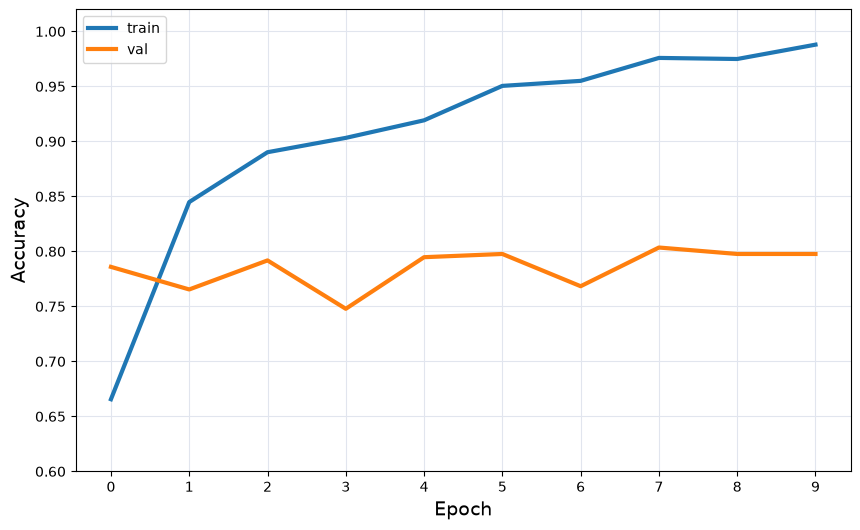

In [89]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.figure(figsize=(10, 6))
plt.plot(acc, linewidth=3, label='train')
plt.plot(val_acc, linewidth=3, label='val')

plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(range(len(acc)))
plt.ylim(0.6, 1.02)
plt.yticks(np.arange(0.6, 1.01, 0.05))
plt.grid(color='#e1e5ee')
plt.legend(loc='upper left')
plt.show()

### Common mistakes

| Mistake | What happens | Fix |
|---|---|---|
| No `label_mode='categorical'` | Labels are integers, which don't work with `CategoricalCrossentropy` | Add it, as in step 2 |
| Using `class_names` after `.map` | The attribute no longer exists on the dataset | Save it first, as in step 3 |
| Running `.map` twice | Images get preprocessed twice and accuracy suffers without a clear error | Re-run the loading cell before `.map` |
| Shuffling validation data | Predictions are harder to match to their images or labels | Keep `shuffle=False` |

# 8.6 Adjusting the learning rate

In the previous unit we trained our first model with transfer learning
and got around 80% accuracy. One parameter we did not tune at all is
the learning rate of the optimizer - and it is one of the most
important hyperparameters of a neural network. In this unit we try
several learning rates, compare the training results, and select the
best one.

## The book analogy

A good way of thinking about the learning rate is to imagine that it
is how fast you read. Say you have a book and you want to read it:

- If you read one book per day, you can get through a lot of books,
  but you're just skimming: you flip through the pages and look at the
  table of contents. When you later try to apply what you learned, you
  don't remember much - you may even forget the first book by the time
  you finish the second.
- If you read one book per quarter, you're not rushing, and you still
  learn enough to apply it.
- If you read one book per year, copying every word into your notebook,
  you'll know that one book really well - but you're making very little
  progress, one page a day.

Reading fast is a high learning rate: you do a lot, but what you learn
is superficial. Reading very slowly is a low learning rate: what you
learn is solid, but it takes forever. Reading maps to training, and
applying what you learned maps to validation:

- With a high learning rate the model does poorly on validation - it
  overfits. It saw a lot, but doesn't generalize.
- With a very low learning rate it also does poorly - it underfits. It
  simply hasn't learned enough yet; it could have learned faster.

A medium learning rate is okay: not the fastest possible learning, but
it generalizes and it actually makes progress. The same idea applies to
neural networks, to gradient boosting, and to many other machine
learning models: if we set the learning rate too high we risk
overfitting, if we set it too low training takes forever, and we need
to find the right balance.

![The book analogy: reading fast is a high learning rate and validates poorly (overfit), reading slowly is a low learning rate and also validates poorly (underfit)](images/06-learning-rate-01-book-analogy-imagegen.jpg)


## Wrapping the model in a function

We select the learning rate the same way we did it for gradient
boosting: try different values, look at plots, and see which one works
best. For that, let's take the code from the previous lesson and put it
into a function - `make_model` - with a parameter `learning_rate`:


In [90]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

Inside, everything is exactly what we had before: the base model with
frozen convolutional layers, the new top with pooling and a dense
layer, then the Adam optimizer - the only thing that changes now is its
learning rate - the categorical cross-entropy loss, and `compile`. The
hash-mark comments just visually separate the parts of the function:
the base model, the new top, and the training setup. We could also move
the middle part into a separate function - something like
`create_architecture` - but let's keep it simple and use the comments.

In [91]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 33s 327ms/step - accuracy: 0.3168 - loss: 2.0001 - val_accuracy: 0.4780 - val_loss: 1.6027
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 327ms/step - accuracy: 0.5535 - loss: 1.3979 - val_accuracy: 0.6158 - val_loss: 1.2432
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 334ms/step - accuracy: 0.6349 - loss: 1.1455 - val_accuracy: 0.6774 - val_loss: 1.0619
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 323ms/step - accuracy: 0.6793 - loss: 1.0022 - val_accuracy: 0.6979 - val_loss: 0.9527
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 317ms/step - accuracy: 0.7109 - loss: 0.9090 - val_accuracy: 0.7067 - val_loss: 0.8828
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 322ms/step - accuracy: 0.7249 - loss: 0.8411 - val_accuracy: 0.7302 - val_loss: 0.8286
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 325ms/step - accuracy: 0.7441 - loss: 0.7881 - val_accuracy: 0.7449 - val_loss: 0.7919
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 319ms/step - accuracy: 0.7585 - loss: 0.7454 - v

We try `0.0001` and `0.001` - smaller than the `0.01` we used before -
and `0.1`, larger. We print the learning rate before each model and two
empty lines after, to make it easier to tell one run from another in
the output. Training four models takes a while - go away, come back in
10-15 minutes.

## Selecting the best learning rate

When it finishes, we don't want to read all those logs. Instead we plot
the accuracies - one curve per learning rate:


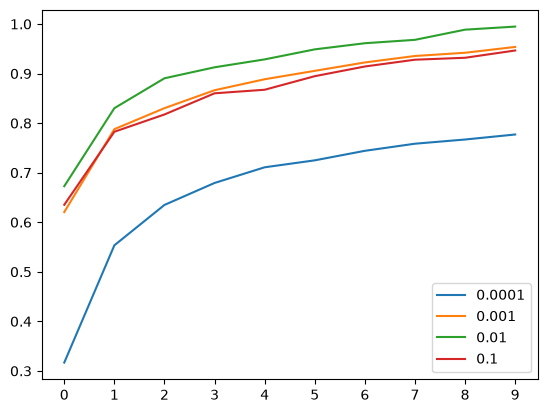

In [92]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

On the training set the smallest learning rate `0.0001` learns too
slowly: after 10 epochs it reaches only about 80% accuracy, while the
others are higher.

Now the same for validation:

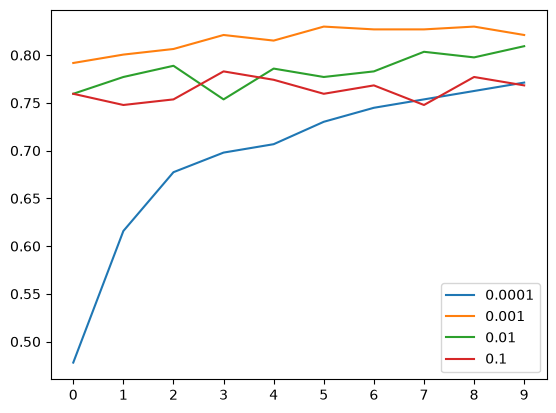

In [93]:
for lr, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [94]:
# Delete the cases that are 'worse'
del scores[0.1] 
del scores[0.0001]

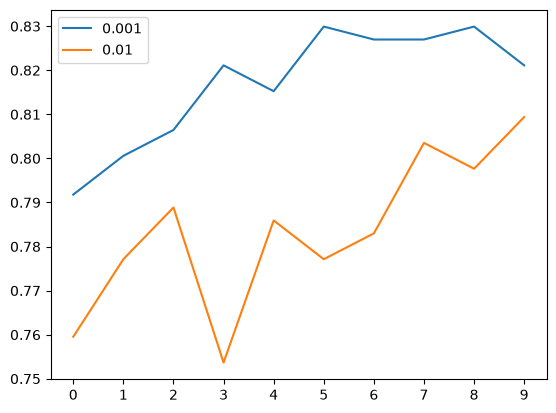

In [95]:
for lr, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

`0.001` is better on validation in general - it's better in all cases
except one, where `0.01` just got lucky. Out of curiosity we can also
plot the training accuracies of these two, with different labels:

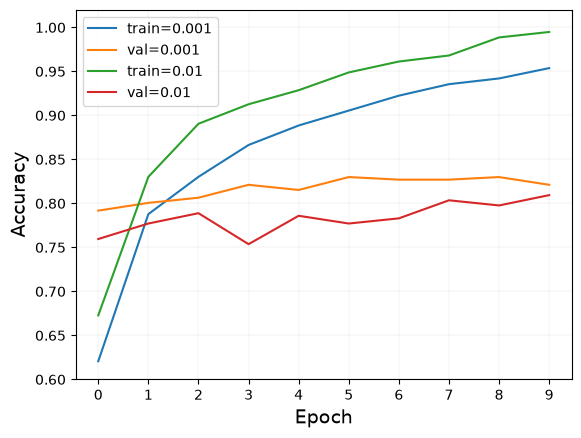

In [114]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('train=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' % lr))


plt.grid(linestyle='-', linewidth=0.1)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(np.arange(10))
plt.ylim(0.6, 1.02)
plt.legend()

It turns out `0.01` is better on the training data, but worse on
validation - the gap between its train and validation curves is bigger.
That's a sign that `0.01` overfits a bit more, and it's another
argument in favor of the smaller learning rate. So the learning rate we
use for training subsequent versions of the model is `0.001`:

In [115]:
learning_rate = 0.001